In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("Food_Delivery_Time_Prediction.csv")

In [3]:
df.head()

,Order_ID,Customer_Location,Restaurant_Location,Distance,Weather_Conditions,Traffic_Conditions,Delivery_Person_Experience,Order_Priority,Order_Time,Vehicle_Type,Restaurant_Rating,Customer_Rating,Delivery_Time,Order_Cost,Tip_Amount
0,ORD0001,"(17.030479, 79.743077)","(12.358515, 85.100083)",1.57,Rainy,Medium,4,Medium,Afternoon,Car,4.1,3.0,26.22,1321.10,81.54
1,ORD0002,"(15.398319, 86.639122)","(14.174874, 77.025606)",21.32,Cloudy,Medium,8,Low,Night,Car,4.5,4.2,62.61,152.21,29.02
2,ORD0003,"(15.687342, 83.888808)","(19.594748, 82.048482)",6.95,Snowy,Medium,9,High,Night,Bike,3.3,3.4,48.43,1644.38,64.17
3,ORD0004,"(20.415599, 78.046984)","(16.915906, 78.278698)",13.79,Cloudy,Low,2,Medium,Evening,Bike,3.2,3.7,111.63,541.25,79.23
4,ORD0005,"(14.786904, 78.706532)","(15.206038, 86.203182)",6.72,Rainy,High,6,Low,Night,Bike,3.5,2.8,32.38,619.81,2.34


In [4]:
df.shape

(200, 15)

In [5]:
df.columns

Index(['Order_ID', 'Customer_Location', 'Restaurant_Location', 'Distance',
       'Weather_Conditions', 'Traffic_Conditions',
       'Delivery_Person_Experience', 'Order_Priority', 'Order_Time',
       'Vehicle_Type', 'Restaurant_Rating', 'Customer_Rating', 'Delivery_Time',
       'Order_Cost', 'Tip_Amount'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 15 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Order_ID                    200 non-null    str    
 1   Customer_Location           200 non-null    str    
 2   Restaurant_Location         200 non-null    str    
 3   Distance                    200 non-null    float64
 4   Weather_Conditions          200 non-null    str    
 5   Traffic_Conditions          200 non-null    str    
 6   Delivery_Person_Experience  200 non-null    int64  
 7   Order_Priority              200 non-null    str    
 8   Order_Time                  200 non-null    str    
 9   Vehicle_Type                200 non-null    str    
 10  Restaurant_Rating           200 non-null    float64
 11  Customer_Rating             200 non-null    float64
 12  Delivery_Time               200 non-null    float64
 13  Order_Cost                  200 non-null    fl

In [7]:
df.describe()

,Distance,Delivery_Person_Experience,Restaurant_Rating,Customer_Rating,Delivery_Time,Order_Cost,Tip_Amount
count,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000
mean,11.498050,5.250000,3.738500,3.686500,70.494950,1046.488700,46.616650
std,6.841755,2.745027,0.703021,0.697063,29.830694,548.568922,29.361706
min,0.520000,1.000000,2.500000,2.600000,15.230000,122.300000,1.240000
25%,6.090000,3.000000,3.200000,3.100000,46.997500,553.270000,21.602500
50%,10.265000,5.000000,3.800000,3.700000,72.775000,1035.950000,47.530000
75%,16.497500,8.000000,4.300000,4.300000,96.650000,1543.125000,70.245000
max,24.900000,10.000000,5.000000,5.000000,119.670000,1997.420000,99.740000


In [8]:
df.isnull().sum()

Order_ID                      0
Customer_Location             0
Restaurant_Location           0
Distance                      0
Weather_Conditions            0
Traffic_Conditions            0
Delivery_Person_Experience    0
Order_Priority                0
Order_Time                    0
Vehicle_Type                  0
Restaurant_Rating             0
Customer_Rating               0
Delivery_Time                 0
Order_Cost                    0
Tip_Amount                    0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.dtypes

Order_ID                          str
Customer_Location                 str
Restaurant_Location               str
Distance                      float64
Weather_Conditions                str
Traffic_Conditions                str
Delivery_Person_Experience      int64
Order_Priority                    str
Order_Time                        str
Vehicle_Type                      str
Restaurant_Rating             float64
Customer_Rating               float64
Delivery_Time                 float64
Order_Cost                    float64
Tip_Amount                    float64
dtype: object

In [11]:
categorical_columns = [
    'Weather_Conditions',
    'Traffic_Conditions',
    'Order_Priority',
    'Order_Time',
    'Vehicle_Type'
]

for column in categorical_columns:
    print("\n", column)
    print(df[column].value_counts())


 Weather_Conditions
Weather_Conditions
Rainy     57
Sunny     53
Snowy     48
Cloudy    42
Name: count, dtype: int64

 Traffic_Conditions
Traffic_Conditions
Low       81
Medium    68
High      51
Name: count, dtype: int64

 Order_Priority
Order_Priority
Low       75
Medium    67
High      58
Name: count, dtype: int64

 Order_Time
Order_Time
Afternoon    59
Evening      57
Night        45
Morning      39
Name: count, dtype: int64

 Vehicle_Type
Vehicle_Type
Bike       69
Bicycle    69
Car        62
Name: count, dtype: int64


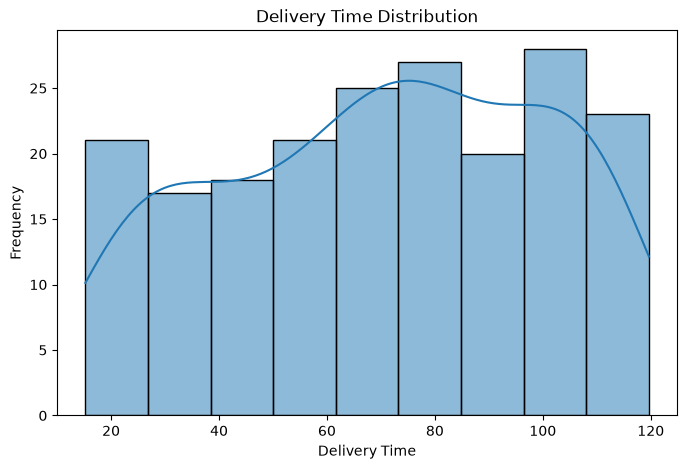

In [12]:
plt.figure(figsize=(8,5))
sns.histplot(df['Delivery_Time'], kde=True)
plt.title('Delivery Time Distribution')
plt.xlabel('Delivery Time')
plt.ylabel('Frequency')
plt.show()

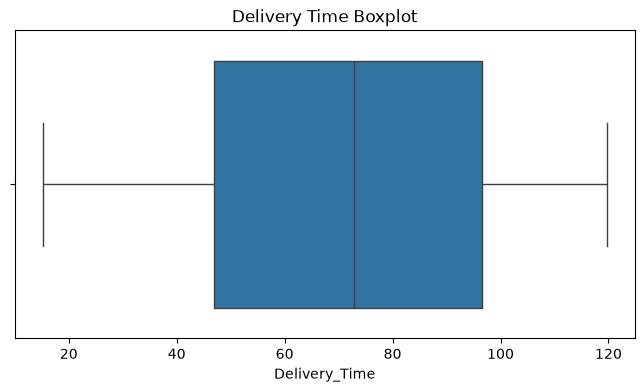

In [13]:
plt.figure(figsize=(8,4))
sns.boxplot(x=df['Delivery_Time'])
plt.title('Delivery Time Boxplot')
plt.show()

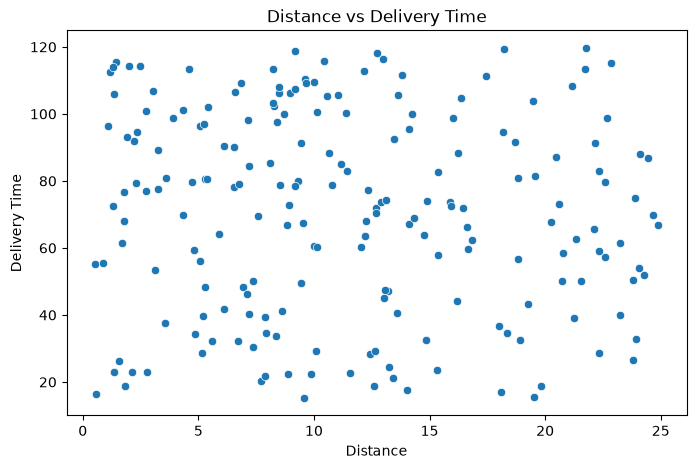

In [14]:
plt.figure(figsize=(8,5))
sns.scatterplot(x=df['Distance'], y=df['Delivery_Time'])
plt.title('Distance vs Delivery Time')
plt.xlabel('Distance')
plt.ylabel('Delivery Time')
plt.show()

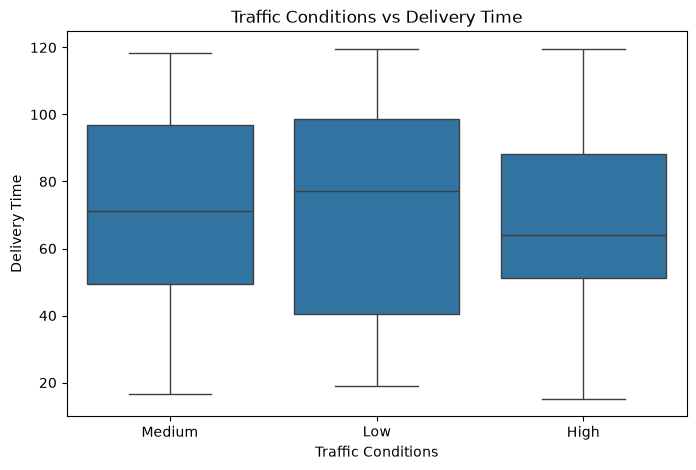

In [15]:
plt.figure(figsize=(8,5))
sns.boxplot(x=df['Traffic_Conditions'], y=df['Delivery_Time'])
plt.title('Traffic Conditions vs Delivery Time')
plt.xlabel('Traffic Conditions')
plt.ylabel('Delivery Time')
plt.show()

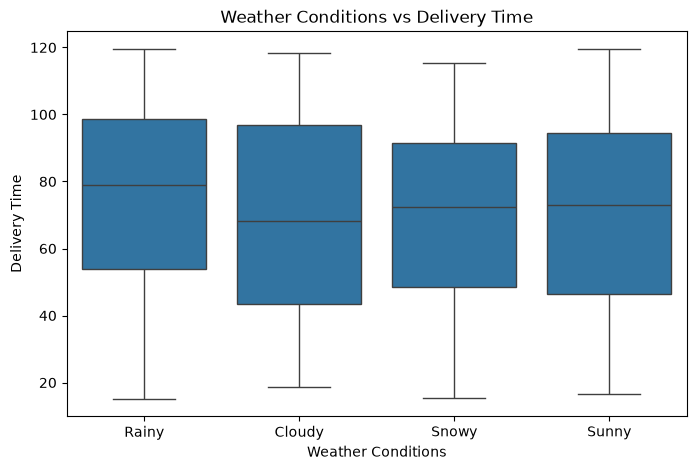

In [16]:
plt.figure(figsize=(8,5))
sns.boxplot(x=df['Weather_Conditions'], y=df['Delivery_Time'])
plt.title('Weather Conditions vs Delivery Time')
plt.xlabel('Weather Conditions')
plt.ylabel('Delivery Time')
plt.show()

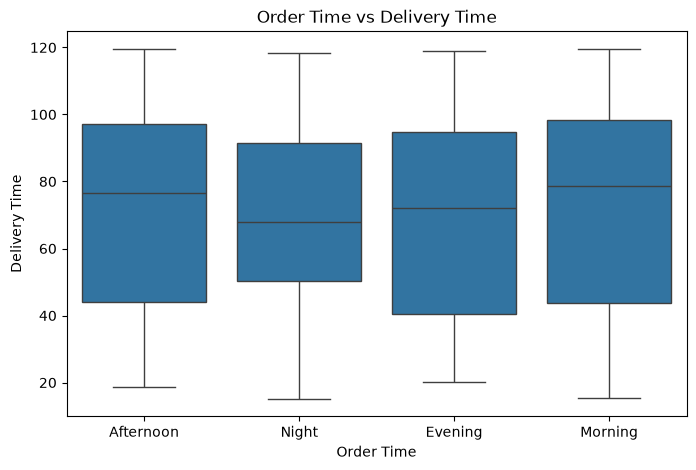

In [17]:
plt.figure(figsize=(8,5))
sns.boxplot(x=df['Order_Time'], y=df['Delivery_Time'])
plt.title('Order Time vs Delivery Time')
plt.xlabel('Order Time')
plt.ylabel('Delivery Time')
plt.show()

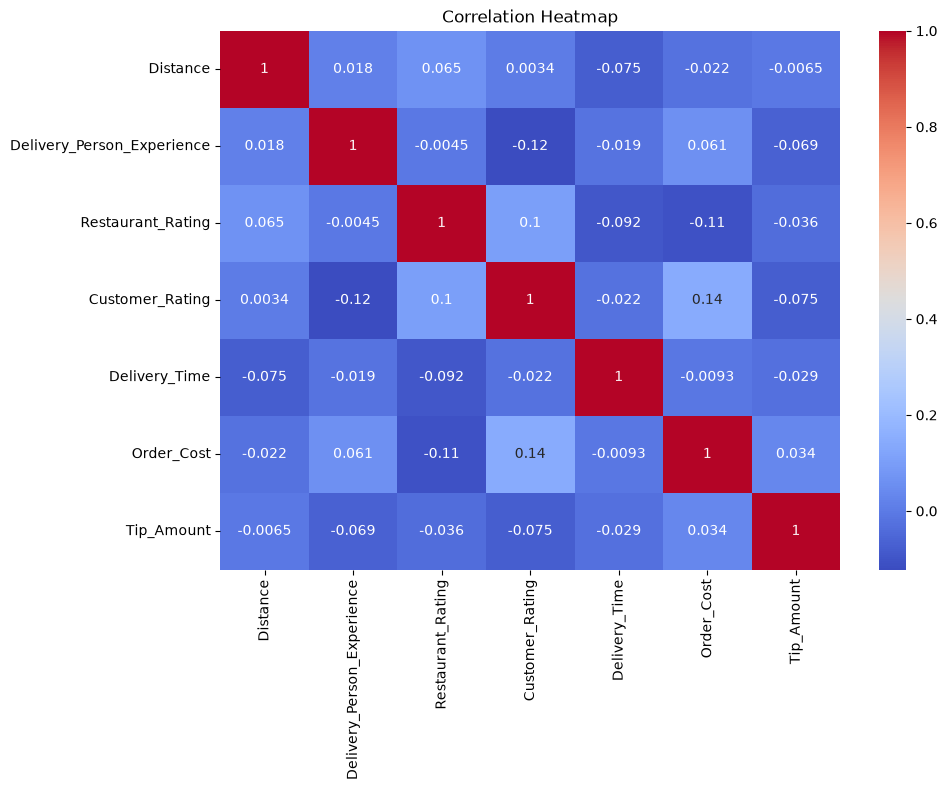

In [18]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(10,7))
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

In [19]:
corr['Delivery_Time'].sort_values(ascending=False)

Delivery_Time                 1.000000
Order_Cost                   -0.009307
Delivery_Person_Experience   -0.019098
Customer_Rating              -0.021952
Tip_Amount                   -0.029154
Distance                     -0.075143
Restaurant_Rating            -0.091855
Name: Delivery_Time, dtype: float64

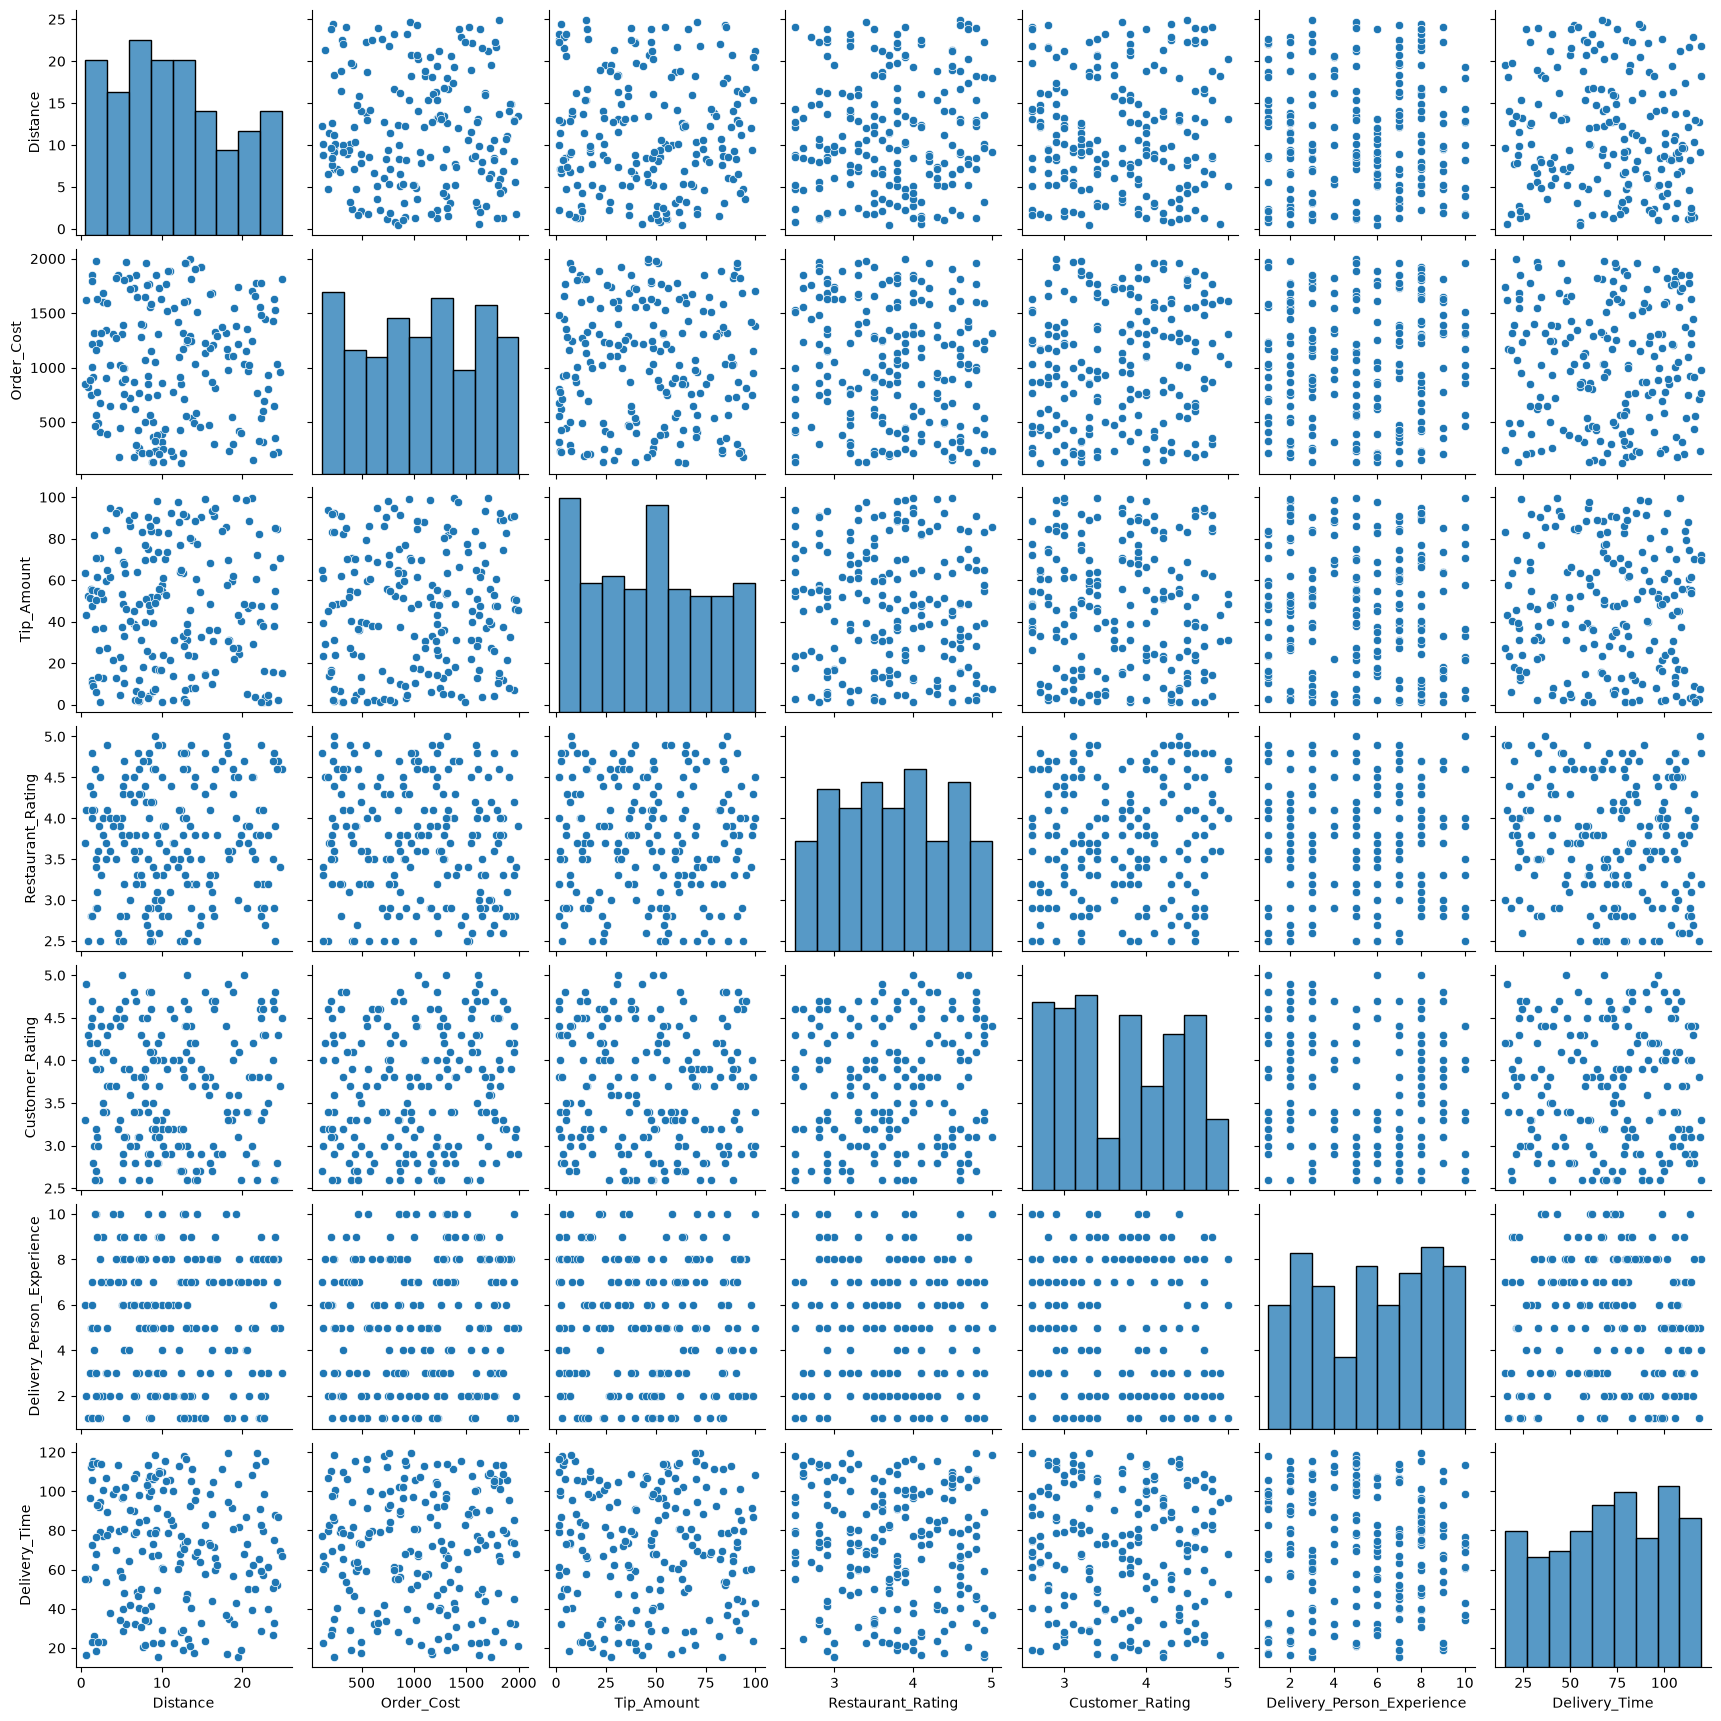

In [20]:
sns.pairplot(df[['Distance', 'Order_Cost', 'Tip_Amount',
                 'Restaurant_Rating', 'Customer_Rating',
                 'Delivery_Person_Experience', 'Delivery_Time']])
plt.show()

In [21]:
df.mean(numeric_only=True)

Distance                        11.49805
Delivery_Person_Experience       5.25000
Restaurant_Rating                3.73850
Customer_Rating                  3.68650
Delivery_Time                   70.49495
Order_Cost                    1046.48870
Tip_Amount                      46.61665
dtype: float64

In [22]:
df.median(numeric_only=True)

Distance                        10.265
Delivery_Person_Experience       5.000
Restaurant_Rating                3.800
Customer_Rating                  3.700
Delivery_Time                   72.775
Order_Cost                    1035.950
Tip_Amount                      47.530
dtype: float64

In [23]:
df.mode(numeric_only=True).iloc[0]

Distance                         1.32
Delivery_Person_Experience       8.00
Restaurant_Rating                3.80
Customer_Rating                  2.60
Delivery_Time                   66.84
Order_Cost                    1813.25
Tip_Amount                       2.22
Name: 0, dtype: float64

In [24]:
df.var(numeric_only=True)

Distance                          46.809617
Delivery_Person_Experience         7.535176
Restaurant_Rating                  0.494239
Customer_Rating                    0.485897
Delivery_Time                    889.870323
Order_Cost                    300927.862112
Tip_Amount                       862.109808
dtype: float64

In [25]:
df[['Customer_Location', 'Restaurant_Location']].head()

,Customer_Location,Restaurant_Location
0,"(17.030479, 79.743077)","(12.358515, 85.100083)"
1,"(15.398319, 86.639122)","(14.174874, 77.025606)"
2,"(15.687342, 83.888808)","(19.594748, 82.048482)"
3,"(20.415599, 78.046984)","(16.915906, 78.278698)"
4,"(14.786904, 78.706532)","(15.206038, 86.203182)"


In [26]:
df['Order_Time'].value_counts()

Order_Time
Afternoon    59
Evening      57
Night        45
Morning      39
Name: count, dtype: int64

In [27]:
from math import radians, sin, cos, sqrt, atan2

def calculate_distance(loc1, loc2):
    lat1, lon1 = map(float, loc1.strip('()').split(','))
    lat2, lon2 = map(float, loc2.strip('()').split(','))

    lat1 = radians(lat1)
    lon1 = radians(lon1)
    lat2 = radians(lat2)
    lon2 = radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = sin(dlat / 2)**2 + cos(lat1) * cos(lat2) * sin(dlon / 2)**2
    c = 2 * atan2(sqrt(a), sqrt(1 - a))

    return 6371 * c

In [28]:
df['Calculated_Distance'] = df.apply(
    lambda row: calculate_distance(
        row['Customer_Location'],
        row['Restaurant_Location']
    ),
    axis=1
)

In [29]:
df[['Customer_Location', 'Restaurant_Location', 'Calculated_Distance']].head()

,Customer_Location,Restaurant_Location,Calculated_Distance
0,"(17.030479, 79.743077)","(12.358515, 85.100083)",775.651198
1,"(15.398319, 86.639122)","(14.174874, 77.025606)",1042.385597
2,"(15.687342, 83.888808)","(19.594748, 82.048482)",476.220706
3,"(20.415599, 78.046984)","(16.915906, 78.278698)",389.912629
4,"(14.786904, 78.706532)","(15.206038, 86.203182)",806.505886


In [30]:
df['Calculated_Distance'].describe()

count     200.000000
mean      603.037915
std       269.796797
min        29.871927
25%       389.197293
50%       558.788921
75%       807.602442
max      1299.244267
Name: Calculated_Distance, dtype: float64

In [31]:
df['Rush_Hour'] = df['Order_Time'].apply(
    lambda x: 1 if x in ['Morning', 'Evening'] else 0
)

In [32]:
df[['Order_Time', 'Rush_Hour']].head(10)

,Order_Time,Rush_Hour
0,Afternoon,0
1,Night,0
2,Night,0
3,Evening,1
4,Night,0
5,Evening,1
6,Evening,1
7,Evening,1
8,Night,0
9,Afternoon,0


In [33]:
df['Rush_Hour'].value_counts()

Rush_Hour
0    104
1     96
Name: count, dtype: int64

In [34]:
X = df.drop(['Delivery_Time', 'Order_ID',
             'Customer_Location', 'Restaurant_Location'], axis=1)

y = df['Delivery_Time']

In [35]:
X.head()

,Distance,Weather_Conditions,Traffic_Conditions,Delivery_Person_Experience,Order_Priority,Order_Time,Vehicle_Type,Restaurant_Rating,Customer_Rating,Order_Cost,Tip_Amount,Calculated_Distance,Rush_Hour
0,1.57,Rainy,Medium,4,Medium,Afternoon,Car,4.1,3.0,1321.10,81.54,775.651198,0
1,21.32,Cloudy,Medium,8,Low,Night,Car,4.5,4.2,152.21,29.02,1042.385597,0
2,6.95,Snowy,Medium,9,High,Night,Bike,3.3,3.4,1644.38,64.17,476.220706,0
3,13.79,Cloudy,Low,2,Medium,Evening,Bike,3.2,3.7,541.25,79.23,389.912629,1
4,6.72,Rainy,High,6,Low,Night,Bike,3.5,2.8,619.81,2.34,806.505886,0


In [36]:
X = pd.get_dummies(X, drop_first=True)

In [37]:
X.head()

,Distance,Delivery_Person_Experience,Restaurant_Rating,Customer_Rating,Order_Cost,Tip_Amount,Calculated_Distance,Rush_Hour,Weather_Conditions_Rainy,Weather_Conditions_Snowy,Weather_Conditions_Sunny,Traffic_Conditions_Low,Traffic_Conditions_Medium,Order_Priority_Low,Order_Priority_Medium,Order_Time_Evening,Order_Time_Morning,Order_Time_Night,Vehicle_Type_Bike,Vehicle_Type_Car
0,1.57,4,4.1,3.0,1321.10,81.54,775.651198,0,True,False,False,False,True,False,True,False,False,False,False,True
1,21.32,8,4.5,4.2,152.21,29.02,1042.385597,0,False,False,False,False,True,True,False,False,False,True,False,True
2,6.95,9,3.3,3.4,1644.38,64.17,476.220706,0,False,True,False,False,True,False,False,False,False,True,True,False
3,13.79,2,3.2,3.7,541.25,79.23,389.912629,1,False,False,False,True,False,False,True,True,False,False,True,False
4,6.72,6,3.5,2.8,619.81,2.34,806.505886,0,True,False,False,False,False,True,False,False,False,True,True,False


In [38]:
X.columns

Index(['Distance', 'Delivery_Person_Experience', 'Restaurant_Rating',
       'Customer_Rating', 'Order_Cost', 'Tip_Amount', 'Calculated_Distance',
       'Rush_Hour', 'Weather_Conditions_Rainy', 'Weather_Conditions_Snowy',
       'Weather_Conditions_Sunny', 'Traffic_Conditions_Low',
       'Traffic_Conditions_Medium', 'Order_Priority_Low',
       'Order_Priority_Medium', 'Order_Time_Evening', 'Order_Time_Morning',
       'Order_Time_Night', 'Vehicle_Type_Bike', 'Vehicle_Type_Car'],
      dtype='str')

In [39]:
import sys
print(sys.version)

3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]


In [40]:
from sklearn.model_selection import train_test_split
print("scikit-learn is working")

scikit-learn is working


In [41]:
import pandas as pd

In [42]:
df = pd.read_csv('Food_Delivery_Time_Prediction.csv')

In [43]:
df.head()

,Order_ID,Customer_Location,Restaurant_Location,Distance,Weather_Conditions,Traffic_Conditions,Delivery_Person_Experience,Order_Priority,Order_Time,Vehicle_Type,Restaurant_Rating,Customer_Rating,Delivery_Time,Order_Cost,Tip_Amount
0,ORD0001,"(17.030479, 79.743077)","(12.358515, 85.100083)",1.57,Rainy,Medium,4,Medium,Afternoon,Car,4.1,3.0,26.22,1321.10,81.54
1,ORD0002,"(15.398319, 86.639122)","(14.174874, 77.025606)",21.32,Cloudy,Medium,8,Low,Night,Car,4.5,4.2,62.61,152.21,29.02
2,ORD0003,"(15.687342, 83.888808)","(19.594748, 82.048482)",6.95,Snowy,Medium,9,High,Night,Bike,3.3,3.4,48.43,1644.38,64.17
3,ORD0004,"(20.415599, 78.046984)","(16.915906, 78.278698)",13.79,Cloudy,Low,2,Medium,Evening,Bike,3.2,3.7,111.63,541.25,79.23
4,ORD0005,"(14.786904, 78.706532)","(15.206038, 86.203182)",6.72,Rainy,High,6,Low,Night,Bike,3.5,2.8,32.38,619.81,2.34


In [44]:
from math import radians, sin, cos, sqrt, atan2

def calculate_distance(loc1, loc2):
    lat1, lon1 = map(float, loc1.strip('()').split(','))
    lat2, lon2 = map(float, loc2.strip('()').split(','))

    lat1 = radians(lat1)
    lon1 = radians(lon1)
    lat2 = radians(lat2)
    lon2 = radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = sin(dlat / 2)**2 + cos(lat1) * cos(lat2) * sin(dlon / 2)**2
    c = 2 * atan2(sqrt(a), sqrt(1 - a))

    return 6371 * c

In [45]:
df['Calculated_Distance'] = df.apply(
    lambda row: calculate_distance(
        row['Customer_Location'],
        row['Restaurant_Location']
    ),
    axis=1
)

In [46]:
df['Rush_Hour'] = df['Order_Time'].apply(
    lambda x: 1 if x in ['Morning', 'Evening'] else 0
)

In [47]:
df[['Calculated_Distance', 'Rush_Hour']].head()

,Calculated_Distance,Rush_Hour
0,775.651198,0
1,1042.385597,0
2,476.220706,0
3,389.912629,1
4,806.505886,0


In [48]:
X = df.drop(['Delivery_Time', 'Order_ID',
             'Customer_Location', 'Restaurant_Location'], axis=1)

y = df['Delivery_Time']

In [49]:
X = pd.get_dummies(X, drop_first=True)

In [50]:
X.head()

,Distance,Delivery_Person_Experience,Restaurant_Rating,Customer_Rating,Order_Cost,Tip_Amount,Calculated_Distance,Rush_Hour,Weather_Conditions_Rainy,Weather_Conditions_Snowy,Weather_Conditions_Sunny,Traffic_Conditions_Low,Traffic_Conditions_Medium,Order_Priority_Low,Order_Priority_Medium,Order_Time_Evening,Order_Time_Morning,Order_Time_Night,Vehicle_Type_Bike,Vehicle_Type_Car
0,1.57,4,4.1,3.0,1321.10,81.54,775.651198,0,True,False,False,False,True,False,True,False,False,False,False,True
1,21.32,8,4.5,4.2,152.21,29.02,1042.385597,0,False,False,False,False,True,True,False,False,False,True,False,True
2,6.95,9,3.3,3.4,1644.38,64.17,476.220706,0,False,True,False,False,True,False,False,False,False,True,True,False
3,13.79,2,3.2,3.7,541.25,79.23,389.912629,1,False,False,False,True,False,False,True,True,False,False,True,False
4,6.72,6,3.5,2.8,619.81,2.34,806.505886,0,True,False,False,False,False,True,False,False,False,True,True,False


In [51]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [52]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(160, 20)
(40, 20)
(160,)
(40,)


In [53]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [54]:
y_pred = model.predict(X_test)

In [55]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MSE:", mse)
print("MAE:", mae)
print("R² Score:", r2)

MSE: 958.8436791374036
MAE: 26.56043960488741
R² Score: -0.03670969012728831


In [56]:
result = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

result.head(10)

,Actual,Predicted
0,91.22,68.700462
1,50.11,72.776336
2,87.96,78.052126
3,95.64,57.431790
4,16.98,75.825691
5,63.79,80.851500
6,72.91,78.523948
7,114.28,65.044130
8,93.20,79.244959
9,28.39,67.441610


In [57]:
df[['Distance', 'Calculated_Distance']].head(10)

,Distance,Calculated_Distance
0,1.57,775.651198
1,21.32,1042.385597
2,6.95,476.220706
3,13.79,389.912629
4,6.72,806.505886
5,10.00,392.168675
6,5.15,638.651532
7,22.57,849.297420
8,13.19,497.049109
9,19.56,416.975418


In [58]:
X = df.drop(['Delivery_Time', 'Order_ID',
             'Customer_Location', 'Restaurant_Location',
             'Calculated_Distance'], axis=1)

y = df['Delivery_Time']

In [59]:
X = pd.get_dummies(X, drop_first=True)

In [60]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [61]:
model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [62]:
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MSE:", mse)
print("MAE:", mae)
print("R² Score:", r2)

MSE: 1021.9359676315077
MAE: 27.184522740542178
R² Score: -0.10492559254945055


In [63]:
df.corr(numeric_only=True)['Delivery_Time'].sort_values(ascending=False)

Delivery_Time                 1.000000
Rush_Hour                     0.005871
Order_Cost                   -0.009307
Delivery_Person_Experience   -0.019098
Customer_Rating              -0.021952
Tip_Amount                   -0.029154
Distance                     -0.075143
Restaurant_Rating            -0.091855
Calculated_Distance          -0.170822
Name: Delivery_Time, dtype: float64

In [64]:
df.groupby('Traffic_Conditions')['Delivery_Time'].mean()

Traffic_Conditions
High      67.567255
Low       71.927284
Medium    70.984559
Name: Delivery_Time, dtype: float64

In [65]:
df.groupby('Weather_Conditions')['Delivery_Time'].mean()

Weather_Conditions
Cloudy    69.786667
Rainy     73.058947
Snowy     69.191250
Sunny     69.479434
Name: Delivery_Time, dtype: float64

In [66]:
df.groupby('Order_Priority')['Delivery_Time'].mean()

Order_Priority
High      70.718621
Low       70.988533
Medium    69.748806
Name: Delivery_Time, dtype: float64

In [67]:
median_time = df['Delivery_Time'].median()
print("Median Delivery Time:", median_time)

Median Delivery Time: 72.775


In [68]:
df['Delivery_Status'] = df['Delivery_Time'].apply(
    lambda x: 0 if x <= median_time else 1
)

In [69]:
df['Delivery_Status'].value_counts()

Delivery_Status
0    100
1    100
Name: count, dtype: int64

In [70]:
X = df.drop([
    'Delivery_Time',
    'Delivery_Status',
    'Order_ID',
    'Customer_Location',
    'Restaurant_Location',
    'Calculated_Distance'
], axis=1)

y = df['Delivery_Status']

In [71]:
X = pd.get_dummies(X, drop_first=True)

In [72]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [73]:
import sklearn

print(sklearn.__version__)


1.5.2


In [74]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop([
    'Delivery_Time',
    'Delivery_Status',
    'Order_ID',
    'Customer_Location',
    'Restaurant_Location',
    'Calculated_Distance'
], axis=1)

y = df['Delivery_Status']

X = pd.get_dummies(X, drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(X_train_scaled.shape)
print(X_test_scaled.shape)

(160, 19)
(40, 19)


In [75]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(max_iter=1000, solver='liblinear')
log_model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000, solver='liblinear')

In [76]:
y_pred_log = log_model.predict(X_test_scaled)
y_prob = log_model.predict_proba(X_test_scaled)[:, 1]

In [77]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [78]:
X_train_scaled.shape

(160, 19)

In [79]:
y_pred_log = log_model.predict(X_test_scaled)
y_prob = log_model.predict_proba(X_test_scaled)[:, 1]

In [80]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Accuracy:", accuracy_score(y_test, y_pred_log))
print("Precision:", precision_score(y_test, y_pred_log))
print("Recall:", recall_score(y_test, y_pred_log))
print("F1 Score:", f1_score(y_test, y_pred_log))

Accuracy: 0.375
Precision: 0.3684210526315789
Recall: 0.35
F1 Score: 0.358974358974359


In [81]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_log)

print(cm)

[[ 8 12]
 [13  7]]


In [82]:
import seaborn as sns
import matplotlib.pyplot as plt

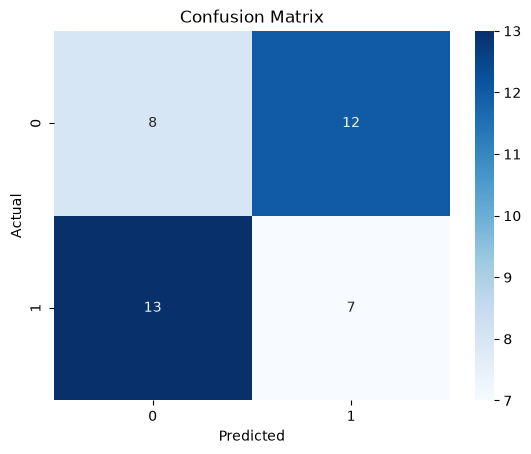

In [83]:
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [84]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

print("AUC:", auc)

AUC: 0.37


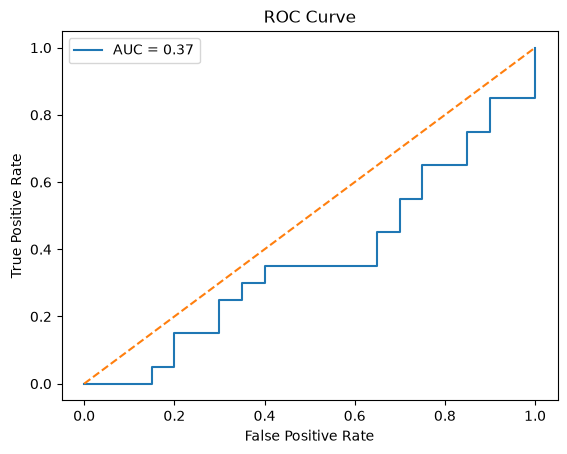

In [85]:
plt.plot(fpr, tpr, label=f'AUC = {auc:.2f}')
plt.plot([0, 1], [0, 1], '--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

In [86]:
comparison = pd.DataFrame({
    'Linear Regression': {
        'MSE': 1021.94,
        'MAE': 27.18,
        'R2 Score': -0.105
    },
    'Logistic Regression': {
        'Accuracy': accuracy_score(y_test, y_pred_log),
        'Precision': precision_score(y_test, y_pred_log),
        'Recall': recall_score(y_test, y_pred_log),
        'F1 Score': f1_score(y_test, y_pred_log),
        'AUC': auc
    }
})

comparison

,Linear Regression,Logistic Regression
MSE,1021.940,NaN
MAE,27.180,NaN
R2 Score,-0.105,NaN
Accuracy,NaN,0.375000
Precision,NaN,0.368421
Recall,NaN,0.350000
F1 Score,NaN,0.358974
AUC,NaN,0.370000


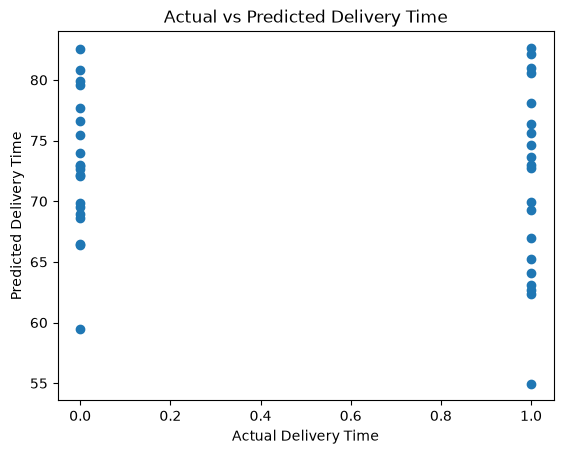

In [87]:
plt.scatter(y_test, y_pred)

plt.xlabel('Actual Delivery Time')
plt.ylabel('Predicted Delivery Time')
plt.title('Actual vs Predicted Delivery Time')
plt.show()

In [88]:
corr = df.corr(numeric_only=True)

corr['Delivery_Time'].sort_values(ascending=False)

Delivery_Time                 1.000000
Delivery_Status               0.847739
Rush_Hour                     0.005871
Order_Cost                   -0.009307
Delivery_Person_Experience   -0.019098
Customer_Rating              -0.021952
Tip_Amount                   -0.029154
Distance                     -0.075143
Restaurant_Rating            -0.091855
Calculated_Distance          -0.170822
Name: Delivery_Time, dtype: float64

In [89]:
df.groupby('Traffic_Conditions')['Delivery_Time'].mean()

Traffic_Conditions
High      67.567255
Low       71.927284
Medium    70.984559
Name: Delivery_Time, dtype: float64

In [90]:
df.groupby('Weather_Conditions')['Delivery_Time'].mean()

Weather_Conditions
Cloudy    69.786667
Rainy     73.058947
Snowy     69.191250
Sunny     69.479434
Name: Delivery_Time, dtype: float64

In [91]:
df.groupby('Order_Priority')['Delivery_Time'].mean()

Order_Priority
High      70.718621
Low       70.988533
Medium    69.748806
Name: Delivery_Time, dtype: float64

## Recommendations

- More data can be collected to improve the prediction.
- Factors like restaurant preparation time and actual traffic conditions can be added.
- Better distance data can be used instead of relying only on the given distance.
- More features related to the delivery person and order can be included.
- Other machine learning models can also be tested to see if the results improve.

## Future Scope

- Use real-time traffic and weather data.
- Add GPS-based route distance.
- Try other machine learning algorithms.
- Collect more delivery records.
- Build a simple application for predicting delivery time.

## Conclusion

In this project, Linear Regression was used to predict delivery time and Logistic Regression was used to classify deliveries as Fast or Delayed. The results showed that the available features had weak relationships with delivery time. The models did not give very high prediction performance, which suggests that more useful features and more data are needed. Still, the project helped in understanding the complete process of data preprocessing, analysis, feature engineering, model building and evaluation.